# Laplacian eigenmodes

`laplacian_eigenmodes(surface, num_modes)` computes the lowest eigenpairs of a triangle surface's Laplace–Beltrami operator: the surface's own Fourier basis, smooth functions ordered by how fast they vary across it. They serve as positional encodings for graph networks and as shape descriptors, and they are a membrane's vibration modes. See `doc/eigenmodes.md`.

In [1]:
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def draw_surface(ax, points, tris, values, title, cmap='coolwarm', view=(20, 35)):
    """A triangle surface coloured by a point field: PyVista's render embedded
    as an image when GL is available, else a matplotlib Poly3DCollection."""
    if pv is not None:
        faces = np.hstack([np.full((len(tris), 1), 3), tris]).ravel()
        grid = pv.PolyData(points, faces)
        grid.point_data['f'] = values
        pl = pv.Plotter(off_screen=True, window_size=(700, 600))
        pl.add_mesh(grid, scalars='f', cmap=cmap, smooth_shading=True)
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        norm = plt.Normalize(np.nanmin(values), np.nanmax(values))
        coll = Poly3DCollection(points[tris], facecolors=plt.get_cmap(cmap)(norm(values[tris].mean(axis=1))),
                                edgecolor='none')
        ax.add_collection3d(coll)
        lim = np.abs(points).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(*view)
        ax.set_axis_off()
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6)
    ax.set_title(title)

No GL available: rendering with matplotlib.


## The sphere: l (l + 1), 2 l + 1 times

On the unit sphere the eigenvalues are `l (l + 1)` with multiplicity `2 l + 1`: the spherical harmonics. The block iteration returns repeated eigenvalues whole.

[ 0.      2.      2.      2.      5.9915  5.9915  5.9915  5.9915  5.9915
 11.9565 11.9565 11.9565 11.9565 11.9584 11.9584 11.9584]
{'iterations': 22, 'max_residual': 4.4452534605244745e-09, 'converged': True}


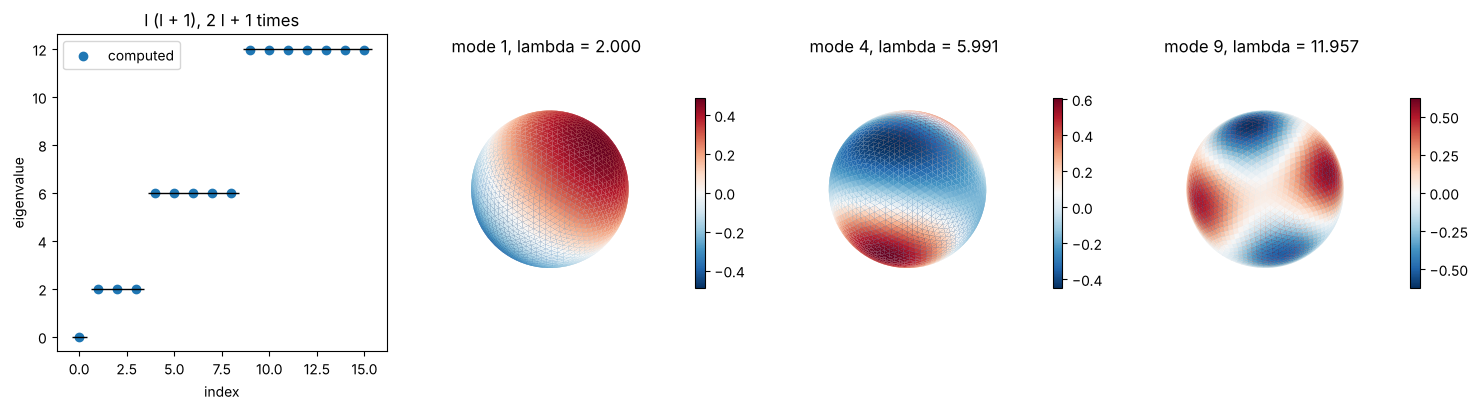

In [2]:
s = mp.icosa_sphere(subdivisions=4)
sphere = mp.Mesh(s.points / np.linalg.norm(s.points, axis=1)[:, None], s.cells)
out, report = mp.laplacian_eigenmodes(sphere, 16, return_report=True)
lam = out.field_data['laplacian:eigenvalues']
print(np.round(lam, 4))
print({k: report[k] for k in ('iterations', 'max_residual', 'converged')})

fig = plt.figure(figsize=(15, 4.2))
ax = fig.add_subplot(1, 4, 1)
ax.plot(range(len(lam)), lam, 'o', label='computed')
for l in range(4):
    ax.hlines(l * (l + 1), l * l - 0.4, (l + 1) ** 2 - 0.6, colors='k', lw=1)
ax.set_xlabel('index'); ax.set_ylabel('eigenvalue'); ax.set_title('l (l + 1), 2 l + 1 times'); ax.legend()
phi = out.point_data['laplacian:modes']
tris = sphere.cells_dict['triangle']
for i, j in enumerate((1, 4, 9)):
    ax = fig.add_subplot(1, 4, i + 2, projection=None if pv else '3d')
    draw_surface(ax, sphere.points, tris, phi[:, j], f'mode {j}, lambda = {lam[j]:.3f}', cmap='RdBu_r')
plt.tight_layout()
plt.show()

## Convergence under refinement

The eigenvalues approach `l (l + 1)` as the sphere is refined; the error of `λ₄` (`l = 2`) falls by about four per refinement, the second-order rate of linear elements.

   162 points: |lambda_1 - 2| = 9.21e-05, |lambda_4 - 6| = 1.36e-01
   642 points: |lambda_1 - 2| = 8.11e-06, |lambda_4 - 6| = 3.41e-02


  2562 points: |lambda_1 - 2| = 6.44e-07, |lambda_4 - 6| = 8.55e-03


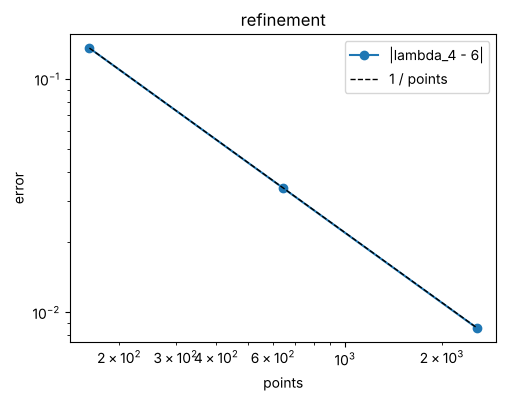

In [3]:
rows = []
for sub in (2, 3, 4):
    s = mp.icosa_sphere(subdivisions=sub)
    m = mp.Mesh(s.points / np.linalg.norm(s.points, axis=1)[:, None], s.cells)
    l = mp.laplacian_eigenmodes(m, 9).field_data['laplacian:eigenvalues']
    rows.append((len(m.points), abs(l[1] - 2), abs(l[4] - 6)))
    print(f'{len(m.points):6d} points: |lambda_1 - 2| = {rows[-1][1]:.2e}, |lambda_4 - 6| = {rows[-1][2]:.2e}')
r = np.array(rows)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(r[:, 0], r[:, 2], 'o-', label='|lambda_4 - 6|')
ax.loglog(r[:, 0], r[0, 2] * r[0, 0] / r[:, 0], 'k--', lw=1, label='1 / points')
ax.set_xlabel('points'); ax.set_ylabel('error'); ax.legend(); ax.set_title('refinement')
plt.show()

## A bracket-like part: modes as positional encodings

On a less regular shape the modes are still smooth, ordered by frequency, and independent of how the points are numbered: renumbering the mesh renumbers the mode values with it and leaves the eigenvalues unchanged.

eigenvalues: [ 0.     5.793  5.793 16.618 31.589 46.519 46.519 56.183]


renumbered eigenvalues agree to 2.3447910280083306e-13


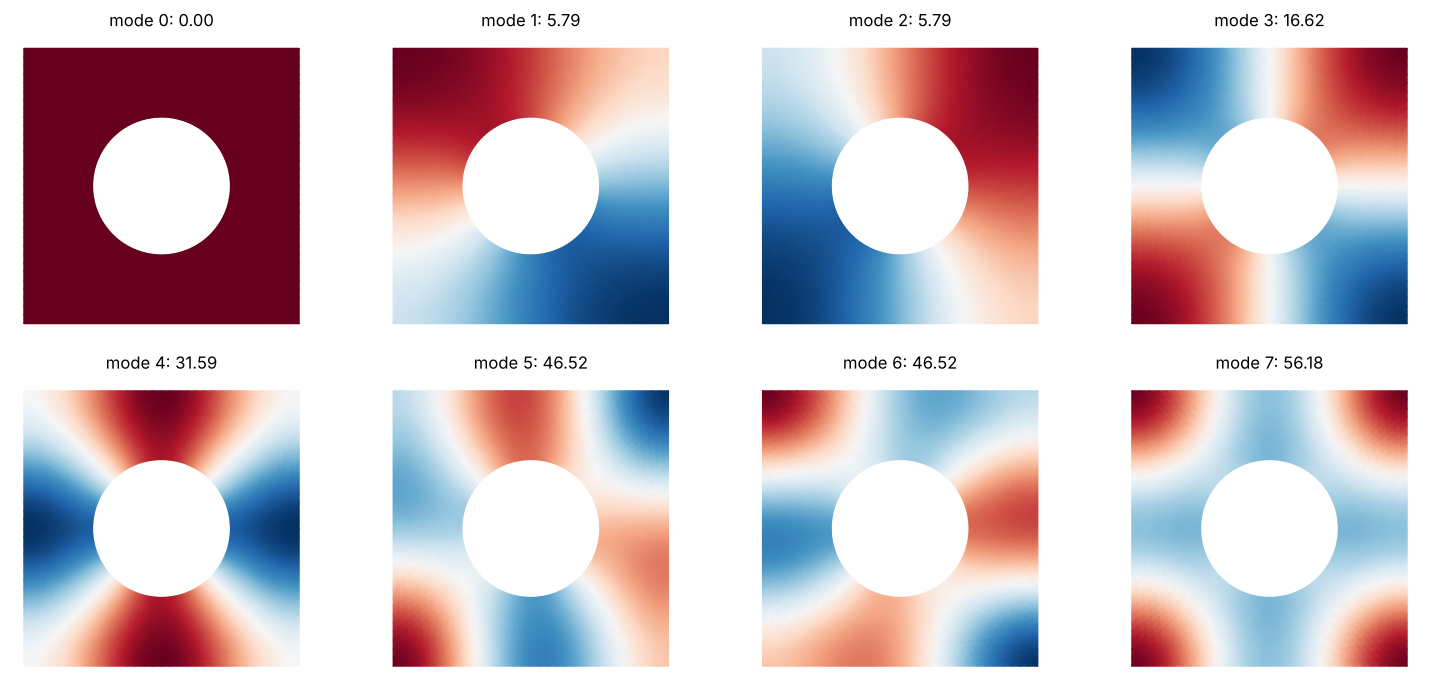

In [4]:
part, _ = mp.apply_operations(None, [
    {"Op": "Generate", "Shape": "plate_with_hole", "Nt": 32, "Nr": 12},
    {"Op": "ConvertCells", "Mode": "simplexify"},
])
pm, prep = mp.laplacian_eigenmodes(part, 8, return_report=True)
phi = pm.point_data['laplacian:modes']
print('eigenvalues:', np.round(prep['eigenvalues'], 3))

perm = np.random.default_rng(0).permutation(len(part.points))
inv = np.argsort(perm)
shuffled = mp.Mesh(part.points[perm], [('triangle', inv[part.cells_dict['triangle']])])
lam2 = mp.laplacian_eigenmodes(shuffled, 8).field_data['laplacian:eigenvalues']
print('renumbered eigenvalues agree to', np.abs(lam2 - prep['eigenvalues']).max())

pts, tris = part.points, part.cells_dict['triangle']
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, ax in enumerate(axes.ravel()):
    a = np.abs(phi[:, j]).max()  # a symmetric scale: the constant mode shows as one colour
    ax.tripcolor(pts[:, 0], pts[:, 1], tris, phi[:, j], shading='gouraud', cmap='RdBu_r', vmin=-a, vmax=a)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(f'mode {j}: {prep["eigenvalues"][j]:.2f}')
plt.tight_layout()
plt.show()

## In a pipeline, and on the command line

The step is `LaplacianEigenmodes`; the verb `eigenmodes` in both CLIs.

In [5]:
_, rep = mp.apply_operations(sphere, [{"Op": "LaplacianEigenmodes", "NumModes": 9}])
print(rep['steps'][0])
print('meshioplusplus eigenmodes skin.stl modes.vtu -k 16 --json')

{'op': 'LaplacianEigenmodes', 'Iterations': 18.0, 'MaxResidual': 4.4406978345408045e-09, 'Converged': 1.0}
meshioplusplus eigenmodes skin.stl modes.vtu -k 16 --json
